# Day8：连续动作的 MADDPG 风格训练闭环

教师提供的分段练习，供 RedMoon 阅读、修改和运行。
两名智能体分别输出一个 [-1,1] 的连续数值；每轮输出后，
团队奖励为 `reward = -(a0-a1)**2`。两轮之后真正终止。
每人只看 `[自己的当前数值, 当前阶段]`，训练 Critic 才看联合观测和动作。

动作是**直接设置新数值**，不是在原数值上再加一个位移。
奖励越接近 0 越好；两人相同就是最优，规则没有指定必须一起选 0。
因而学会固定共同约定可以成功，当前任务不要求通信或跟随不可见随机提示。
不要把“两人都输出一个常数”解释成网络知道了队友本轮秘密信息。

本次包括真实交互、联合回放、两个局部 Actor、两个集中式 Q Critic、
四个目标副本、TD 更新、保留动作梯度、软同步和完整两轮评估。
使用确定性 tanh Actor 与外加高斯探索噪声，按 MADDPG 的连续动作更新机制教学；
没有照搬作者旧 TensorFlow 实现的随机分布、策略正则、集成或 MPE benchmark。

## 1. 配置：环境步、参数更新、软同步分别计数

| 变量 | 含义 |
|---|---|
| `num_episodes` | 双方共同训练多少局，每局两次联合环境转移 |
| `start_steps` | 前多少环境步完全随机探索，也用于预热回放 |
| `batch_size` | 每次随机抽多少条完整联合转移 |
| `actor_lr / critic_lr` | 两种网络各自的优化器学习率 |
| `gamma` | 第一步 TD 目标中下一步评分的折扣 |
| `tau` | 软同步时在线参数所占的比例，旧目标占 1-tau |
| `noise_start / noise_end` | 探索高斯噪声的起始、最终标准差 |
| `gap_tolerance` | 评估时将数值差不超过 0.1 定义为该轮达标 |

每次可训练的环境步，两个 Critic 和两个 Actor 各更新一次。
`joint_updates` 计一整轮四个优化器更新，`optimizer_steps` 则计实际 step 调用。
学习率、折扣、噪声和 tau 是不同概念。

In [1]:
import os
if os.name == "nt":
    os.environ["MKL_THREADING_LAYER"] = "SEQUENTIAL"

import copy
import itertools
import json
import random
from collections import deque
from typing import NamedTuple

import torch
from torch import nn
from torch.nn import functional as F
import matplotlib.pyplot as plt

seed = 7
torch.manual_seed(seed)
torch.set_num_threads(1)
device = torch.device("cpu")  # 极小网络用 CPU 即可。
num_episodes, start_steps, batch_size = 2500, 256, 128
replay_capacity = 5000
gamma, tau = 0.9, 0.01
actor_lr, critic_lr = 0.0005, 0.002
noise_start, noise_end = 0.3, 0.08
gap_tolerance = 0.1
checks_passed = 0

def check(condition, name):
    global checks_passed
    assert bool(condition), name
    checks_passed += 1
    print("PASS:", name)

print("PyTorch:", torch.__version__, "| device:", device)
print("共同回合 / 每次批量 / 预热环境步:",
      num_episodes, batch_size, start_steps)

PyTorch: 2.10.0+cu128 | device: cpu
共同回合 / 每次批量 / 预热环境步: 2500 128 256


## 2. 环境：两轮都行动，终点之后不再计算未来

`phase=0/1` 分别表示第一、第二轮，`phase=2` 是终点。
`positions` 保存双方刚设置的数值。初始数值随机，但最终目标不由初值决定。
先同时得到两个动作，再调用一次 `step`；不能让后行动的人偷看另一人的本轮动作。

第一轮 `(0.2,0.8)` 得 -0.36，第二轮 `(0.5,0.5)` 得 0。
本局总奖励是 -0.36，起点折扣回报也是 -0.36；
第一步还要估计未来，第二步 `terminated=True` 后 TD 目标就是当步奖励。

In [2]:
class TwoRoundAgreementEnv:
    def __init__(self, seed):
        self.rng = random.Random(seed)
        self.finished = True
        self.reset_count = self.step_count = 0

    def reset(self, initial=None):
        self.positions = (
            tuple(float(x) for x in initial) if initial is not None else
            (self.rng.uniform(-1, 1), self.rng.uniform(-1, 1))
        )
        self.phase, self.finished = 0, False
        self.reset_count += 1
        return (*self.positions, self.phase)

    def step(self, actions):
        if self.finished:
            raise RuntimeError("本局已经终止，请先 reset")
        assert len(actions) == 2 and all(-1 <= a <= 1 for a in actions)
        self.positions = tuple(float(a) for a in actions)
        reward = -(self.positions[0] - self.positions[1]) ** 2
        self.phase += 1
        self.finished = self.phase == 2
        self.step_count += 1
        return (*self.positions, self.phase), reward, self.finished

def local_observations(state):
    # 第 0 人拿到 [x0,phase]，第 1 人拿到 [x1,phase]。
    x0, x1, phase = state
    return torch.tensor(
        [[x0, phase], [x1, phase]], dtype=torch.float32, device=device,
    )

demo_env = TwoRoundAgreementEnv(seed)
demo_env.reset((-0.7, 0.6))
demo_s1, demo_r0, demo_t0 = demo_env.step((0.2, 0.8))
demo_s2, demo_r1, demo_t1 = demo_env.step((0.5, 0.5))
check(abs(demo_r0 + 0.36) < 1e-8, "第一轮奖励由动作差平方决定")
check(not demo_t0 and demo_t1, "完整两轮后才真正终止")
check(demo_s2 == (0.5, 0.5, 2), "动作直接设置新数值")
check(torch.equal(local_observations((-0.7, 0.6, 0))[0],
                  local_observations((-0.7, -0.9, 0))[0]),
      "改变队友数值不改变本人局部观测")
print("环境示例:", demo_s1, demo_r0, demo_t0,
      "->", demo_s2, demo_r1, demo_t1)

PASS: 第一轮奖励由动作差平方决定
PASS: 完整两轮后才真正终止
PASS: 动作直接设置新数值
PASS: 改变队友数值不改变本人局部观测
环境示例: (0.2, 0.8, 1) -0.3600000000000001 False -> (0.5, 0.5, 2) -0.0 True


## 3. 网络：每人一个 Actor、一个 Critic，再各配目标副本

Actor 输入 `[自己的数值,阶段]`，输出一个动作；最后用 tanh 将输出限制在 [-1,1]。
Critic 输入双方观测和动作，共 2+2+1+1=6 个数，输出该角色的 Q。
本例共享奖励，因此两份 Critic 都拟合团队回报；独立参数并不自动给出责任分摊。

为让训练前差距可见，两个 Actor 的输出层初始偏置设为 +0.6/-0.6；
这是公开的教学初始化，不是动作标签，网络仍要通过环境奖励学习。
Critic 使用普通 MLP，没有写入解析奖励或正确动作。
四个目标副本最初完整复制在线参数；训练目标不回传，稍后通过软同步跟随。

In [3]:
class LocalActor(nn.Module):
    def __init__(self, initial_bias):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, 32), nn.Tanh(),
            nn.Linear(32, 32), nn.Tanh(),
            nn.Linear(32, 1), nn.Tanh(),
        )
        with torch.no_grad():
            self.net[-2].bias.fill_(initial_bias)

    def forward(self, own_observation):
        return self.net(own_observation)

class CentralCritic(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(6, 32), nn.Tanh(),
            nn.Linear(32, 32), nn.Tanh(),
            nn.Linear(32, 1),
        )

    def forward(self, obs, actions):
        # obs 为 [B,2,2]，actions 为 [B,2,1]；B 表示批量。
        inputs = torch.cat(
            [obs.flatten(start_dim=1), actions.flatten(start_dim=1)], dim=1,
        )
        return self.net(inputs)  # [B,1]，每条经历对应一个 Q。

actors = [LocalActor(0.6).to(device), LocalActor(-0.6).to(device)]
critics = [CentralCritic().to(device) for _ in range(2)]
target_actors = copy.deepcopy(actors)
target_critics = copy.deepcopy(critics)
for target in target_actors + target_critics:
    target.requires_grad_(False)
actor_optimizers = [torch.optim.Adam(a.parameters(), lr=actor_lr) for a in actors]
critic_optimizers = [torch.optim.Adam(c.parameters(), lr=critic_lr) for c in critics]

def snapshot(modules):
    return [p.detach().clone() for m in modules for p in m.parameters()]

def unchanged(modules, saved):
    return all(torch.equal(p.detach(), old)
               for p, old in zip((p for m in modules for p in m.parameters()), saved))

initial_actors = [snapshot([a]) for a in actors]
initial_critics = [snapshot([c]) for c in critics]
initial_targets = snapshot(target_actors + target_critics)
probe_obs = local_observations((0.2, 0.8, 0)).unsqueeze(0)
probe_actions = torch.zeros(1, 2, 1, device=device)
check(actors[0](probe_obs[:, 0]).shape == (1, 1), "Actor 输出 [B,1]")
check(critics[0](probe_obs, probe_actions).shape == (1, 1), "Critic 输出 [B,1]")

PASS: Actor 输出 [B,1]
PASS: Critic 输出 [B,1]


## 4. 联合回放：抽中一行，就同时取出双方同一步的经历

`Transition` 保存一次真实环境转移，不保存永久固定的 TD 目标。
一条记录中，观测 `[2,2]`、实际动作 `[2,1]`、奖励 `[2,1]`，
下一观测 `[2,2]`、共同终止标记 `[1]` 全部来自同局同一时刻。
两人共同奖励相同，在两个位置各存一份以便逐角色读取，不能在 TD 中相加。

`stack` 在最前面加一个批量维度 B。抽样只打乱完整转移之间的顺序，
不分别打乱两人的动作，也不将别人另一局的奖励拼过来。
本任务没有被隐藏的历史提示，局部 MLP 的当前输入足够表达固定约定。

In [4]:
class Transition(NamedTuple):
    obs: torch.Tensor
    actions: torch.Tensor
    rewards: torch.Tensor
    next_obs: torch.Tensor
    terminated: torch.Tensor

replay = deque(maxlen=replay_capacity)
replay_rng = random.Random(seed + 1)
exploration_rng = random.Random(seed + 2)

def save_transition(state, actions, reward, next_state, terminated):
    replay.append(Transition(
        local_observations(state),
        torch.tensor(actions, dtype=torch.float32, device=device).view(2, 1),
        torch.full((2, 1), reward, dtype=torch.float32, device=device),
        local_observations(next_state),
        torch.tensor([float(terminated)], dtype=torch.float32, device=device),
    ))

def sample_batch():
    rows = replay_rng.sample(list(replay), batch_size)
    return Transition(*(torch.stack(field) for field in zip(*rows)))

## 5. TD 目标与软同步：目标 Actor 负责下一步动作

```text
下一联合动作 = 两个目标 Actor 分别读取各自下一观测
y_i = 本人保存奖励 + gamma * (1-terminated) * 目标 Critic 的下一步 Q
```

这里是连续动作，不用 argmax 在两个动作编号中挑选。
两个目标 Actor 直接生成下一联合动作，目标 Critic 给它评分。
目标分支整体放进 `no_grad`，因为 y 是本次拟合的固定参照。

`target = (1-tau)*old_target + tau*online` 对四个目标网络分别执行；
tau=0.01 的意思是本次引入 1% 在线参数，而非每 100 步硬复制一次。
网络没有 BatchNorm 等状态缓冲区，当前只需同步参数。

In [5]:
@torch.no_grad()
def td_targets(batch):
    next_actions = torch.stack(
        [target_actors[i](batch.next_obs[:, i]) for i in range(2)], dim=1,
    )  # [B,2,1]，不是回放中旧的下一动作。
    targets = []
    for i in range(2):
        next_q = target_critics[i](batch.next_obs, next_actions)
        y = batch.rewards[:, i] + gamma * (1 - batch.terminated) * next_q
        targets.append(y)
    return targets

@torch.no_grad()
def soft_update(online, target):
    for online_p, target_p in zip(online.parameters(), target.parameters()):
        target_p.mul_(1 - tau).add_(online_p, alpha=tau)

## 6. 一整轮更新：Critic 学评分，Actor 沿动作梯度学选择

先固定两个 TD 目标，然后分别更新两个 Critic。
Critic 用的是**真实执行的回放动作**，因为保存奖励属于那组动作。

更新 Actor i 时，构造 `[本人当前动作, 队友回放动作]`；
只替换本人那一项，不训练队友 Actor。这与作者 `p_train` 的动作分工相同。
Critic 暂停参数梯度，但本人动作保留计算图；随后最小化 `-Q.mean()`。
最后四个目标副本软同步。`zero_grad` 清除旧梯度，不能代替冻结参数。

本例 Actor 和 Critic 完全独立，没有共享参数、dropout 或归一化运行统计。
最小化预测的 -Q 不保证每次真实回报提高，所以后面必须实际执行完整轨迹。

In [6]:
def update_from_replay():
    batch = sample_batch()
    targets = td_targets(batch)
    critic_losses, actor_losses, actor_grad_norms = [], [], []

    for i in range(2):
        q = critics[i](batch.obs, batch.actions)
        loss = F.mse_loss(q, targets[i])
        critic_optimizers[i].zero_grad(set_to_none=True)
        loss.backward()
        critic_optimizers[i].step()
        critic_losses.append(loss.item())

    for i in range(2):
        critic = critics[i]
        # 刚才 Critic 更新产生过梯度，先清除，避免误读为 Actor 造成的梯度。
        critic_optimizers[i].zero_grad(set_to_none=True)
        critic.requires_grad_(False)
        own_action = actors[i](batch.obs[:, i])  # 不 detach。
        action_parts = [batch.actions[:, j] for j in range(2)]
        action_parts[i] = own_action
        actions_for_actor = torch.stack(action_parts, dim=1)
        loss = -critic(batch.obs, actions_for_actor).mean()
        actor_optimizers[i].zero_grad(set_to_none=True)
        loss.backward()
        grad_norm = sum(p.grad.square().sum() for p in actors[i].parameters())
        actor_grad_norms.append(grad_norm.sqrt().item())
        actor_optimizers[i].step()
        critic.requires_grad_(True)
        actor_losses.append(loss.item())

    for online, target in zip(actors + critics, target_actors + target_critics):
        soft_update(online, target)
    return critic_losses, actor_losses, actor_grad_norms

## 7. 冻结评估：关闭额外噪声，只让局部 Actor 完成两轮

评估固定 9×9=81 种初始数值组合，并另采 500 个连续随机起点。
`eval()` 设置网络模式，`no_grad()` 停止记录计算图；
**真正关闭探索的是不再给动作加高斯噪声**，这三件事各有职责。

记录每轮差距、总奖励、起点折扣回报和两轮都达标的比例。
成功率依赖本练习的差距阈值 0.1；它不等于精确相等，也不代表一般最优保证。
`evaluate` 的输入只包含两个 Actor，没有向它传入 Critic、目标网络或回放。

In [7]:
@torch.no_grad()
def local_actions(actor_models, state):
    obs = local_observations(state)
    return tuple(actor_models[i](obs[i:i+1]).item() for i in range(2))

@torch.no_grad()
def evaluate(actor_models, initials, keep_traces=False):
    for actor in actor_models:
        actor.eval()
    eval_env = TwoRoundAgreementEnv(seed + 100)
    gaps, totals, discounted, successes, traces = [], [], [], [], []
    for initial in initials:
        state = eval_env.reset(initial)
        finished, step, total, g0, success = False, 0, 0.0, 0.0, True
        trace = []
        while not finished:
            actions = local_actions(actor_models, state)
            next_state, reward, finished = eval_env.step(actions)
            gap = abs(actions[0] - actions[1])
            gaps.append(gap)
            total += reward
            g0 += gamma ** step * reward
            success = success and gap <= gap_tolerance
            if keep_traces:
                trace.append({"state": state, "actions": actions,
                              "reward": reward, "terminated": finished})
            state, step = next_state, step + 1
        assert step == 2  # 真正走完第二轮，不能只检查第一步。
        totals.append(total)
        discounted.append(g0)
        successes.append(success)
        if keep_traces:
            traces.append(trace)
    return {
        "episodes": len(totals), "environment_steps": eval_env.step_count,
        "mean_gap": sum(gaps) / len(gaps), "max_gap": max(gaps),
        "mean_reward": sum(totals) / len(totals),
        "mean_discounted": sum(discounted) / len(discounted),
        "success_rate": sum(successes) / len(successes), "traces": traces,
    }

grid = torch.linspace(-1, 1, 9).tolist()
grid_initials = list(itertools.product(grid, repeat=2))
initial_eval = evaluate(actors, grid_initials)
print("训练前冻结评估:", {k: v for k, v in initial_eval.items() if k != "traces"})

训练前冻结评估: {'episodes': 81, 'environment_steps': 162, 'mean_gap': 0.8093279889888234, 'max_gap': 0.9724707007408142, 'mean_reward': -1.3418710396193354, 'mean_discounted': -1.29513727359784, 'success_rate': 0.0}


## 8. 真实训练：采样、存回放、更新、软同步，直到本局终点

预热期直接均匀随机选动作，之后使用 `Actor 输出 + 高斯噪声` 并裁到 [-1,1]。
回放存的是**加噪声并裁剪后真正执行的动作**，不是原始 Actor 输出。
Gaussian 噪声只负责探索，没有告诉网络哪组动作正确。

第 256 次环境转移后开始批量更新。每 200 局和最后一局，用相同 81 个起点
关闭探索评估一次；评估用独立环境，不增加训练计数、不改变回放或抽样随机数。
训练曲线和冻结曲线的探索条件不同，不能直接拿两者数值判断策略退步。

In [8]:
train_env = TwoRoundAgreementEnv(seed + 3)
environment_steps = joint_updates = target_syncs = 0
episode_rewards, critic_loss_history, actor_loss_history = [], [], []
gradient_history = []
checkpoints = [(0, initial_eval["mean_gap"], initial_eval["mean_reward"])]

for episode in range(num_episodes):
    state, finished, total_reward = train_env.reset(), False, 0.0
    noise_std = noise_start + (noise_end - noise_start) * episode / (num_episodes - 1)
    while not finished:
        if environment_steps < start_steps:
            actions = tuple(exploration_rng.uniform(-1, 1) for _ in range(2))
        else:
            clean_actions = local_actions(actors, state)
            actions = tuple(
                max(-1.0, min(1.0, a + exploration_rng.gauss(0, noise_std)))
                for a in clean_actions
            )
        next_state, reward, finished = train_env.step(actions)
        save_transition(state, actions, reward, next_state, finished)
        environment_steps += 1
        total_reward += reward

        if environment_steps >= start_steps:
            c_losses, a_losses, grad_norms = update_from_replay()
            joint_updates += 1
            target_syncs += 1  # 一次计四个目标网络都完成软同步。
            critic_loss_history.append(sum(c_losses) / 2)
            actor_loss_history.append(sum(a_losses) / 2)
            gradient_history.append(grad_norms)
        state = next_state

    episode_rewards.append(total_reward)
    if (episode + 1) % 200 == 0 or episode + 1 == num_episodes:
        current = evaluate(actors, grid_initials)
        checkpoints.append((episode + 1, current["mean_gap"], current["mean_reward"]))
        print(f"回合 {episode+1:4d} | 冻结平均差 {current['mean_gap']:.4f}"
              f" | 两轮均值奖励 {current['mean_reward']:.4f}")

final_eval = evaluate(actors, grid_initials)
print("训练环境步 / 一整轮更新 / 实际 optimizer.step / 完整软同步:",
      environment_steps, joint_updates, 4 * joint_updates, target_syncs)

回合  200 | 冻结平均差 0.0110 | 两轮均值奖励 -0.0004
回合  400 | 冻结平均差 0.1131 | 两轮均值奖励 -0.0485
回合  600 | 冻结平均差 0.0571 | 两轮均值奖励 -0.0121
回合  800 | 冻结平均差 0.0523 | 两轮均值奖励 -0.0076
回合 1000 | 冻结平均差 0.0324 | 两轮均值奖励 -0.0034
回合 1200 | 冻结平均差 0.0223 | 两轮均值奖励 -0.0019
回合 1400 | 冻结平均差 0.0406 | 两轮均值奖励 -0.0044
回合 1600 | 冻结平均差 0.0220 | 两轮均值奖励 -0.0020
回合 1800 | 冻结平均差 0.0281 | 两轮均值奖励 -0.0033
回合 2000 | 冻结平均差 0.0358 | 两轮均值奖励 -0.0036
回合 2200 | 冻结平均差 0.0330 | 两轮均值奖励 -0.0028
回合 2400 | 冻结平均差 0.0159 | 两轮均值奖励 -0.0011
回合 2500 | 冻结平均差 0.0187 | 两轮均值奖励 -0.0014
训练环境步 / 一整轮更新 / 实际 optimizer.step / 完整软同步: 5000 4745 18980 4745


## 9. 验证分工：目标不回传，本人动作回传，评估不调用 Critic

检查实际回放批次中的终止转移 y=reward。
梯度检查复用当前模型，但只求导、不执行优化器；不会额外训练模型。
Critic 冻结时评分仍连接本人 Actor；detach 后这条连接消失。
`autograd.grad` 直接返回梯度，不把它累积进 `.grad`。

In [9]:
audit_batch = sample_batch()
audit_targets = td_targets(audit_batch)
check(audit_batch.obs.shape == (batch_size, 2, 2)
      and audit_batch.actions.shape == (batch_size, 2, 1),
      "回放双方观测与动作维度配对")
check(audit_batch.rewards.shape == (batch_size, 2, 1)
      and audit_batch.terminated.shape == (batch_size, 1),
      "奖励与终止标记没有批次广播错位")
check(all(y.shape == (batch_size, 1) and not y.requires_grad for y in audit_targets),
      "两份 TD 目标 [B,1] 且不回传")
terminal_mask = audit_batch.terminated[:, 0].bool()
check(terminal_mask.any() and (~terminal_mask).any(), "抽样含第一轮和真正终止步")
check(all(torch.equal(y[terminal_mask], audit_batch.rewards[:, i][terminal_mask])
          for i, y in enumerate(audit_targets)),
      "真正终止的目标只保留当前奖励")

frozen_critic = critics[0]
frozen_critic.requires_grad_(False)
current_action = actors[0](audit_batch.obs[:, 0])
actor_actions = torch.stack([current_action, audit_batch.actions[:, 1]], dim=1)
live_loss = -frozen_critic(audit_batch.obs, actor_actions).mean()
actor_grads = torch.autograd.grad(live_loss, tuple(actors[0].parameters()))
check(any(g.abs().sum().item() > 0 for g in actor_grads),
      "Critic 参数冻结时仍有 Actor 梯度")
detached_actions = torch.stack(
    [current_action.detach(), audit_batch.actions[:, 1]], dim=1,
)
detached_loss = -frozen_critic(audit_batch.obs, detached_actions).mean()
check(not detached_loss.requires_grad, "detach 本人动作会切断本例评分计算图")
check(all(p.grad is None for p in frozen_critic.parameters()),
      "Actor 更新没有积累 Critic 参数梯度")
frozen_critic.requires_grad_(True)
check(all(not unchanged([a], old) for a, old in zip(actors, initial_actors)),
      "两个 Actor 参数都经过真实训练更新")
check(all(not unchanged([c], old) for c, old in zip(critics, initial_critics)),
      "两个 Critic 参数都经过真实训练更新")
check(not unchanged(target_actors + target_critics, initial_targets)
      and all(p.grad is None for m in target_actors + target_critics for p in m.parameters()),
      "目标参数通过同步改变，未从 loss 获得梯度")
check(environment_steps == num_episodes * 2 and train_env.reset_count == num_episodes,
      "训练每局完整两轮")
check(joint_updates == environment_steps - start_steps + 1
      and target_syncs == joint_updates,
      "联合更新与软同步计数准确")
check(torch.isfinite(torch.tensor(critic_loss_history + actor_loss_history)).all()
      and torch.isfinite(torch.tensor(gradient_history)).all(),
      "训练损失与 Actor 梯度没有 NaN 或无穷")
check(final_eval["mean_gap"] < initial_eval["mean_gap"],
      "相同冻结条件下平均差距实际下降")

online_and_targets = actors + critics + target_actors + target_critics
before_eval = snapshot(online_and_targets)
counts = {"critic": 0, "target_actor": 0}
def count_critic(module, inputs, output):
    counts["critic"] += 1
def count_target_actor(module, inputs, output):
    counts["target_actor"] += 1
hooks = [m.register_forward_hook(count_critic) for m in critics + target_critics]
hooks += [m.register_forward_hook(count_target_actor) for m in target_actors]
eval_rng = random.Random(seed + 200)
random_initials = [(eval_rng.uniform(-1, 1), eval_rng.uniform(-1, 1)) for _ in range(500)]
sampled_eval = evaluate(actors, random_initials)
trace_eval = evaluate(actors, [(-1, 1), (0.7, -0.3)], keep_traces=True)
for hook in hooks:
    hook.remove()
check(counts == {"critic": 0, "target_actor": 0}, "分散评估仅调用局部在线 Actor")
check(unchanged(online_and_targets, before_eval), "评估不修改任何网络参数")
check(sampled_eval["environment_steps"] == 1000
      and all(len(t) == 2 and not t[0]["terminated"] and t[1]["terminated"]
              for t in trace_eval["traces"]), "冻结评估和展示轨迹均走到第二轮终点")
print("500 个随机起点评估:",
      {k: v for k, v in sampled_eval.items() if k != "traces"})
for trace in trace_eval["traces"]:
    print("完整轨迹:", trace)

PASS: 回放双方观测与动作维度配对
PASS: 奖励与终止标记没有批次广播错位
PASS: 两份 TD 目标 [B,1] 且不回传
PASS: 抽样含第一轮和真正终止步
PASS: 真正终止的目标只保留当前奖励
PASS: Critic 参数冻结时仍有 Actor 梯度
PASS: detach 本人动作会切断本例评分计算图
PASS: Actor 更新没有积累 Critic 参数梯度
PASS: 两个 Actor 参数都经过真实训练更新
PASS: 两个 Critic 参数都经过真实训练更新
PASS: 目标参数通过同步改变，未从 loss 获得梯度
PASS: 训练每局完整两轮
PASS: 联合更新与软同步计数准确
PASS: 训练损失与 Actor 梯度没有 NaN 或无穷
PASS: 相同冻结条件下平均差距实际下降
PASS: 分散评估仅调用局部在线 Actor
PASS: 评估不修改任何网络参数
PASS: 冻结评估和展示轨迹均走到第二轮终点
500 个随机起点评估: {'episodes': 500, 'environment_steps': 1000, 'mean_gap': 0.016862876534461974, 'max_gap': 0.079456627368927, 'mean_reward': -0.001141896331015463, 'mean_discounted': -0.0011323660715573136, 'success_rate': 1.0}
完整轨迹: [{'state': (-1.0, 1.0, 0), 'actions': (0.4085571765899658, 0.36399519443511963), 'reward': -0.0019857702535688304, 'terminated': False}, {'state': (0.4085571765899658, 0.36399519443511963, 1), 'actions': (0.45484402775764465, 0.43752217292785645), 'reward': -0.00030004665474425707, 'terminated': True}]
完整轨迹: [{'state': (0.7, -0.3, 0)

## 10. 读结果：差距、真实回报、实际动作各看一张图

左图比较同样 81 个起点、关闭噪声时的平均动作差距。
中图显示训练真实奖励的 100 局滚动均值及冻结评估奖励；
训练有探索，所以两条曲线可以不同，评分接近 0 表示一致程度提高。
右图沿同一个初始状态画出两轮实际动作，检查两人如何靠近。
图中动作来自环境执行，不是 Critic 预测，也没有预设“正确共同数值”。

Critic loss 随机批次均值可用于排查拟合，但任务是否达标要看完整真实轨迹。
由于存在许多等价最优约定，不强求动作等于 0，也不按正负号判断动作好坏。

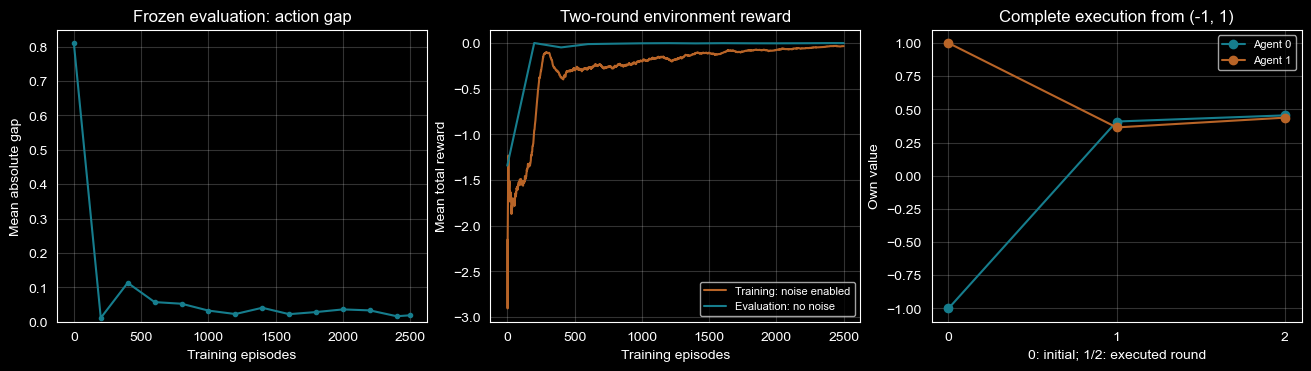

SUMMARY_JSON={"seed": 7, "device": "cpu", "pytorch": "2.10.0+cu128", "training_episodes": 2500, "training_environment_steps": 5000, "joint_updates": 4745, "optimizer_steps": 18980, "target_syncs": 4745, "replay_size": 5000, "initial_mean_gap": 0.8093279889888234, "final_mean_gap": 0.018730927212738696, "initial_mean_reward": -1.3418710396193354, "final_mean_reward": -0.001405086695189038, "final_grid_success_rate": 1.0, "sampled_mean_gap": 0.016862876534461974, "sampled_max_gap": 0.079456627368927, "sampled_mean_reward": -0.001141896331015463, "sampled_successes": 500, "training_last100_reward": -0.03444699654635592, "last50_critic_loss": 0.000199625520981499, "execution_calls": {"critic": 0, "target_actor": 0}, "complete_traces": [[{"state": [-1.0, 1.0, 0], "actions": [0.4085571765899658, 0.36399519443511963], "reward": -0.0019857702535688304, "terminated": false}, {"state": [0.4085571765899658, 0.36399519443511963, 1], "actions": [0.45484402775764465, 0.43752217292785645], "reward": 

In [10]:
def rolling_mean(values, window=100):
    return [sum(values[max(0, i-window+1):i+1]) / min(i+1, window)
            for i in range(len(values))]

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), constrained_layout=True)
episodes, mean_gaps, eval_rewards = zip(*checkpoints)
axes[0].plot(episodes, mean_gaps, marker="o", markersize=3, color="#167d8d")
axes[0].set(title="Frozen evaluation: action gap",
            xlabel="Training episodes", ylabel="Mean absolute gap")
axes[0].set_ylim(bottom=0)
axes[1].plot(range(1, num_episodes+1), rolling_mean(episode_rewards),
             color="#b86427", label="Training: noise enabled")
axes[1].plot(episodes, eval_rewards, color="#167d8d", label="Evaluation: no noise")
axes[1].set(title="Two-round environment reward",
            xlabel="Training episodes", ylabel="Mean total reward")
axes[1].legend(fontsize=8)
first_trace = trace_eval["traces"][0]
for i, color in enumerate(("#167d8d", "#b86427")):
    values = [first_trace[0]["state"][i]] + [step["actions"][i] for step in first_trace]
    axes[2].plot([0, 1, 2], values, marker="o", color=color, label=f"Agent {i}")
axes[2].set(title="Complete execution from (-1, 1)",
            xlabel="0: initial; 1/2: executed round", ylabel="Own value",
            xticks=[0, 1, 2], ylim=(-1.1, 1.1))
axes[2].legend(fontsize=8)
for ax in axes:
    ax.grid(alpha=0.2)
plt.show()

summary = {
    "seed": seed, "device": str(device), "pytorch": torch.__version__,
    "training_episodes": num_episodes, "training_environment_steps": environment_steps,
    "joint_updates": joint_updates, "optimizer_steps": 4 * joint_updates,
    "target_syncs": target_syncs, "replay_size": len(replay),
    "initial_mean_gap": initial_eval["mean_gap"], "final_mean_gap": final_eval["mean_gap"],
    "initial_mean_reward": initial_eval["mean_reward"],
    "final_mean_reward": final_eval["mean_reward"],
    "final_grid_success_rate": final_eval["success_rate"],
    "sampled_mean_gap": sampled_eval["mean_gap"],
    "sampled_max_gap": sampled_eval["max_gap"],
    "sampled_mean_reward": sampled_eval["mean_reward"],
    "sampled_successes": round(sampled_eval["success_rate"] * 500),
    "training_last100_reward": sum(episode_rewards[-100:]) / 100,
    "last50_critic_loss": sum(critic_loss_history[-50:]) / 50,
    "execution_calls": counts, "complete_traces": trace_eval["traces"],
    "checks_passed": checks_passed,
}
print("SUMMARY_JSON=" + json.dumps(summary, ensure_ascii=True))

### 当前保存输出：数值怎样对应到训练过程

2026-10-11，默认 seed=7、CPU、PyTorch 2.11.0+cpu 实际执行。
两个干净内核得到完全相同的摘要；自己重跑后，以自己这次的输出为准。

| 比较项目 | 训练前 | 训练后 | 怎么读 |
|---|---:|---:|---|
| 同样 81 个起点的平均动作差 | 0.809328 | 0.018731 | 越小代表双方数值越接近 |
| 同样起点的两轮平均总奖励 | -1.341871 | -0.001405 | 越接近 0 越好，因为奖励是负的差距平方 |

训练共 2500 个共同回合、5000 次联合环境转移。
第 256 个环境步开始更新，包含该步，因此联合更新是 5000-256+1=4745 轮。
每轮两个 Actor、两个 Critic 各 step 一次，共 18980 次优化器 step；
4745 次完整软同步，每次同时更新四个目标副本。计数没有将评估环境步算进训练。

另外 500 个连续随机起点，平均差为 0.016863，最大差为 0.079457，
两轮平均总奖励为 -0.001142，500/500 局满足两轮差距都不超过 0.1。
这个成功率对应本例阈值；平均差仍非零，没有达到每一步精确相等。
分散执行中 Critic 和目标 Actor 的调用都为 0，所有网络参数保持不变。

从 (-1,1) 出发的真实完整轨迹：

| 轮次 | Actor 0 动作 | Actor 1 动作 | 实际奖励 | 本局是否终止 |
|---|---:|---:|---:|---|
| 第一轮 | 0.408557 | 0.363995 | -0.001986 | 否 |
| 第二轮 | 0.454844 | 0.437522 | -0.000300 | 是 |

每人的动作直接成为自己的新数值。双方最后靠近约 0.45，而非必须输出 0；
奖励只要求一致，换成接近另一个共同数值也可以成功。
右图从初始数值画到第一轮、第二轮，最后一个点确实对应终点。

最后 100 局训练平均奖励为 -0.034447，比关闭噪声的评估更低。
训练最终仍保留标准差约 0.08 的独立高斯噪声，两人各自探索会拉开差距。
不能据此判断参数突然变差；公平比较要使用相同起点和相同探索条件。

最后 50 轮平均 Critic loss 约 0.00019963；它比较不同回放批次和变化的 TD 目标，
不能用这个数替代环境轨迹，或认定 Critic 在所有动作上的导数都准确。
左图在第 200 局已经很低，第 400 局又升高，随后再次降低；
有限批次、同时变化的队友策略和近似 Q 都可能造成波动，曲线没有单调下降保证。

24 项检查覆盖转移规则、张量配对、终止目标、动作梯度、参数更新、计数和冻结评估。
本例证明这条具体训练与评估链路能工作，不将结果解释成学会了通信。

## 11. 用本例连接 Day6、Day7 与 Day8

- Day6 通信任务：隐藏提示每局随机变化，接收者行动前需要收到有效消息。
  本例奖励只要求两人一致，因此稳定共同约定就能成功，没有学消息通道。
- Day7 QMIX：局部网络给离散动作评分，各自 argmax；训练的 Mixer 将局部评分混合。
  本例 Actor 直接输出连续动作，集中式 Q 对联合动作评分，用动作导数训练 Actor。
- 两种方法都可以集中训练、分散执行，评估时都要遵守局部信息边界。
  集中式 Critic 的训练输入不会自动成为 Actor 执行时的输入。
- 本例两个 Critic 都拟合同一个共同回报；没有 COMA 反事实 baseline，
  因此不能把它们各自输出的 Q 解释为个人责任比例。

更新机制参考 Lowe 等的 MADDPG 论文第 4.1 节和 OpenAI 作者实现：
作者 Actor 更新替换本人动作、保留队友回放动作，目标分支使用下一联合动作，
目标参数通过 Polyak 同步。本例省去作者源码的策略分布和正则项，
使用明确的确定性连续 Actor；不以一个种子或这个小任务证明算法比较优势。